# Laboratorio de regresión - 3

## Análisis exploratorio de datos y limpieza

|                |   |
:----------------|---|
| **Nombre**     |  Alexa Bojorquez Valdivia |
| **Fecha**      |  10 de octubre |
| **Expediente** |  745497 |

En los laboratorios y clases anteriores se ha visto que el modelo de regresión propuesto puede ser cualquier combinación lineal de factores independientes. Por lo tanto hay un número infinito de posibles modelos de regresión teóricos. ¿Cómo podemos deducir qué tipo de modelo podríamos necesitar?

- Primero necesitamos conocer y explorar nuestros datos. Podemos revisar qué variables tenemos, sus distribuciones y cómo se relacionan entre ellas para después decidir qué modelo podría ajustarse mejor.

### EDA

El primer paso antes de poder proponer un modelo para predecir datos es entender el conjunto de datos con el que se está trabajando.
- ¿Cuántas muestras tiene?
- ¿Cuántos factores tiene?
- ¿Quién o qué hizo la recolección de las observaciones?
- ¿Cómo se hizo el muestreo?
- ¿En qué año se hicieron las observaciones?
- ¿En dónde se realizaron las observaciones?

El propósito de un análisis exploratorio de datos (EDA - Exploratory Data Analysis) es entender la naturaleza de los datos, comprender las relaciones existentes entre las variables para poder realizar hipótesis sobre cómo se relaciona la variable dependiente con las independientes.

#### Ejercicio 1: Dataset

Utiliza el dataset "Heart Prediction Dataset (Quantum)". Carga los datos y revisa qué factores contiene.

In [1]:
import pandas as pd

data = pd.read_csv("Heart Prediction Quantum Dataset.csv")

In [2]:
data.head()

,Age,Gender,BloodPressure,Cholesterol,HeartRate,HeartDisease
0,68,Hombre,105.00,191,107,1
1,58,Mujer,97.00,249,89,0
2,44,Mujer,93.00,190,82,1
3,72,Hombre,93.00,183,101,1
4,37,Mujer,145.00,166,103,1


In [3]:
data.columns

Index(['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate',
       'HeartDisease'],
      dtype='str')

In [4]:
data.shape

(500, 6)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            500 non-null    int64
 1   Gender         500 non-null    str  
 2   BloodPressure  500 non-null    str  
 3   Cholesterol    500 non-null    int64
 4   HeartRate      500 non-null    int64
 5   HeartDisease   500 non-null    int64
dtypes: int64(4), str(2)
memory usage: 29.3 KB


In [6]:
data.describe()

,Age,Cholesterol,HeartRate,HeartDisease
count,500.000000,500.00000,500.000000,500.000000
mean,54.864000,221.50000,88.766000,0.600000
std,14.315004,43.86363,17.417289,0.490389
min,30.000000,150.00000,60.000000,0.000000
25%,43.000000,183.75000,73.000000,0.000000
50%,55.000000,221.00000,89.000000,1.000000
75%,66.250000,258.00000,104.000000,1.000000
max,79.000000,299.00000,119.000000,1.000000


Para cada factor, escribe qué significa cada variable.
- ¿Qué tipo de datos se observaron?
    - Numéricos
        - Enteros
        - Flotantes
    - Categóricos
        - Ordinales
        - No ordinales
- ¿Qué rango de valores sería esperado que contuviera cada factor? E.g. No esperaría encontrar un valor de Age de $-4$.

Investiga los valores esperados para variables que no entiendas como BloodPressure, Cholesterol, etc.

Age: edad de la persona. Es una variable numérica entera. Se esperan edades positivas y dentro de un rango posible para una persona.

Gender: género de la persona. Es una variable categórica no ordinal, ya que sus categorías no tienen un orden.

BloodPressure: presión arterial. Es una variable numérica, aunque inicialmente aparece como texto por inconsistencias en su formato.

Cholesterol: nivel de colesterol. Es una variable numérica y sus valores deben ser positivos.

HeartRate: frecuencia cardiaca o latidos por minuto. Es una variable numérica y debe contener valores positivos y posibles para una persona.

HeartDisease: indica la presencia de enfermedad cardiaca. Es una variable categórica binaria donde 0 indica que no y 1 que sí.

In [10]:
print(data['Gender'].value_counts())
print(data['BloodPressure'].value_counts())

Gender
Mujer        208
Hombre       149
Hombre        66
mujer         43
Hombre}       18
MUJER          7
Mujer{         5
MUjer          3
ombre          1
Name: count, dtype: int64
BloodPressure
140.00    11
115.00    10
94.00      8
159.00     8
118.00     8
          ..
117.00     1
154.00     1
137,00     1
174,00     1
147.00     1
Name: count, Length: 156, dtype: int64


El dataset contiene información de 500 personas y diferentes factores relacionados con su salud cardiovascular. Incluye edad, género, presión arterial, colesterol, frecuencia cardiaca y si presenta o no una enfermedad cardiaca. Hay variables numéricas y categóricas, por lo que primero es necesario revisar y limpiar los datos antes de analizarlos.

A partir de lo investigado, describe el dataset con tus palabras.

#### Ejercicio 2: Factores

Ahora que se tiene un mejor entendimiento del dataset y de los valores que podría tener cada variable, es momento de revisar que las observaciones en el dataset estén dentro de ese rango esperado.

Crea un histograma para cada uno de los factores para ver el rango de los valores medidos y su distribución. 

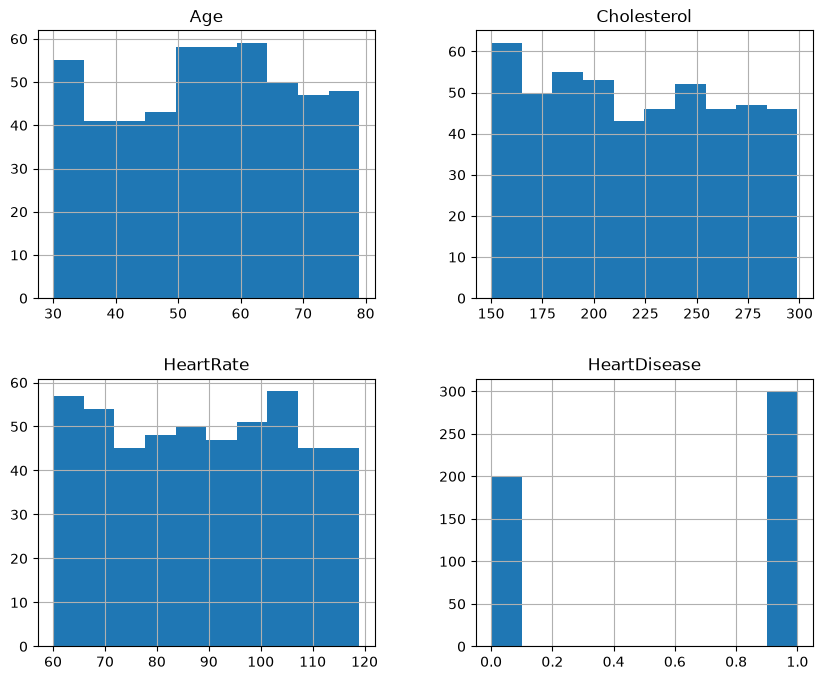

In [11]:
import matplotlib.pyplot as plt

data.hist(figsize=(10, 8))
plt.show()

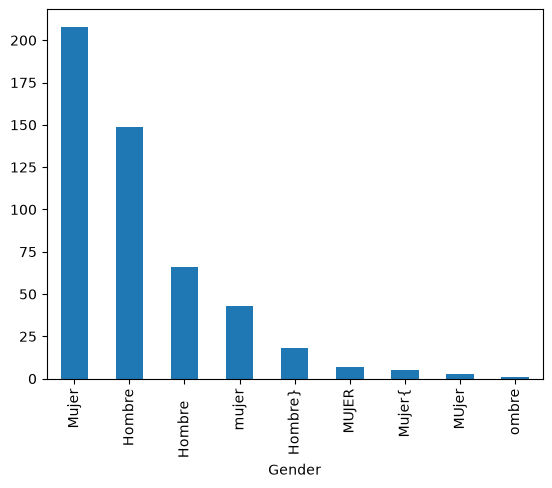

In [12]:
data['Gender'].value_counts().plot(kind='bar')
plt.show()

In [13]:
data['BloodPressure'].value_counts()

BloodPressure
140.00    11
115.00    10
94.00      8
159.00     8
118.00     8
          ..
117.00     1
154.00     1
137,00     1
174,00     1
147.00     1
Name: count, Length: 156, dtype: int64

¿Parecen correctas estas distribuciones? ¿Qué valores atípicos encontraste? ¿Alguna inconsistencia? ¿Los problemas encontrados podrían ser casos reales?

- En general los valores numéricos parecen estar dentro de rangos posibles, pero si se encontraron inconsistencias. Gender tiene las mismas categorías escritas de diferentes maneras y BloodPressure aparece como texto porque se utilizaron diferentes formatos para el punto decimal. Estos problemas parecen errores al capturar los datos y no categorías o valores diferentes reales.

#### Ejercicio 3: Limpieza

Es muy común que haya errores al registrar observaciones. Puede ser que personas diferentes hayan registrado datos con un estilo diferente, o que haya habido un error de dedo. También podrían haber registros duplicados, o datos faltantes.

Por ejemplo, la columna BloodPressure tiene dos estilos diferentes para el punto decimal (americano y europeo).

Utiliza `pandas.Series.str.replace` para cambiar el punto decimal de europeo a americano en la columna de BloodPressure. Después, cambia el tipo de dato de la columna a numérico. Dibuja el histograma de la variable corregida.

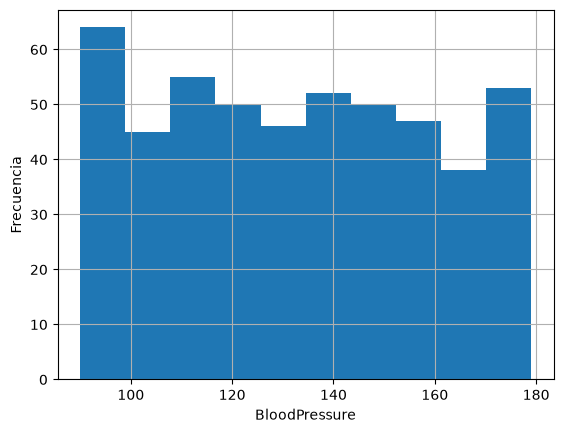

In [14]:
data['BloodPressure'] = data['BloodPressure'].str.replace(',', '.')
data['BloodPressure'] = pd.to_numeric(data['BloodPressure'])

data['BloodPressure'].hist()
plt.xlabel('BloodPressure')
plt.ylabel('Frecuencia')
plt.show()

La columna Gender tiene también errores de dedo y de estilo. Utiliza `pandas.Series.unique()` para encontrar las formas diferentes en las que se escribió "Hombre" y "Mujer".

In [15]:
data['Gender'].unique()

<ArrowStringArray>
['Hombre   ',     'Mujer',     'ombre',     'mujer',     'MUjer',     'MUJER',
    'Mujer{',   'Hombre}',    'Hombre']
Length: 9, dtype: str

La diferencia entre una mayúscula y minúscula para una computadora tiene que ver con la tabla ASCII. Para evitar esta variación utiliza `pandas.Series.str.lower()` para convertir todos las mayúsculas en minúsculas. Guarda el resultado en una variable auxiliar. Utiliza `unique()` una vez más para ver el resultado.

In [16]:
gender = data['Gender'].str.lower()

gender.unique()

<ArrowStringArray>
['hombre   ', 'mujer', 'ombre', 'mujer{', 'hombre}', 'hombre']
Length: 6, dtype: str

Observamos que hay errores como espacios en blanco o errores de dedo. Utiliza `pandas.Series.str.rstrip("xxx")` para limpiar los caracteres indeseados.

In [17]:
gender = gender.str.rstrip(' }{')

gender.unique()

<ArrowStringArray>
['hombre', 'mujer', 'ombre']
Length: 3, dtype: str

Utiliza un filtro para corregir el typo de la 'h' faltante para la categoría "hombre".

In [21]:
gender[gender == 'ombre'] = 'hombre'

gender.unique()

<ArrowStringArray>
['hombre', 'mujer']
Length: 2, dtype: str

Asigna "hombre"=1 y "mujer"=0 (Ojo con los tipos de dato. Considera que 0 es diferente a "0").

In [24]:
gender = gender.replace({'hombre': 1, 'mujer': 0})
gender.unique()

array([1, 0], dtype=object)

In [25]:
gender = gender.astype(int)

Reescribe el resultado en el dataset original.

In [26]:
data['Gender'] = gender

Para asegurarnos que no haya duplicados, utiliza `pd.DataFrame.drop_duplicates()`

In [27]:
data.duplicated().sum()

np.int64(0)

In [28]:
data = data.drop_duplicates()

Para los valores faltantes se podría imputar, pero por ahora sólo elimínalos (si es que hay) con `pd.DataFrame.dropna()`

In [29]:
data = data.dropna()

#### Ejercicio 4: Verificación

Ahora que entendemos qué significan nuestras variables y que las limpiamos, vuelve a generar histogramas para cada variable.

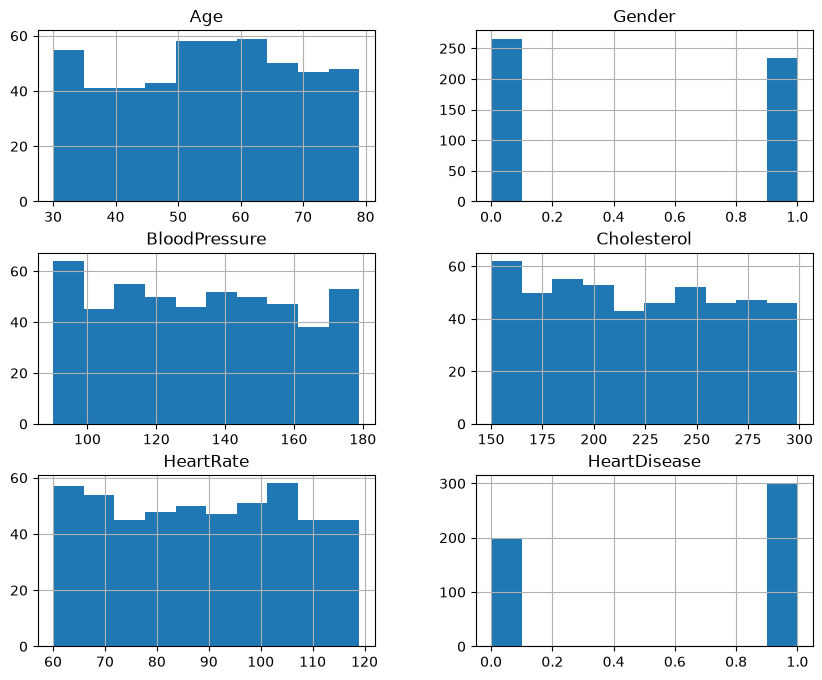

In [30]:
data.hist(figsize=(10, 8))
plt.show()

Encuentra la siguiente información para las variables numéricas:
- media
- mediana
- desviación estándar
- mínimo
- máximo

Genera un diagrama de caja para cada una. ¿Consideras que hay valores atípicos (outliers)?

In [31]:
numericas = data[['Age', 'BloodPressure', 'Cholesterol', 'HeartRate']]

numericas.describe()

,Age,BloodPressure,Cholesterol,HeartRate
count,500.000000,500.000000,500.00000,500.000000
mean,54.864000,132.874000,221.50000,88.766000
std,14.315004,26.418516,43.86363,17.417289
min,30.000000,90.000000,150.00000,60.000000
25%,43.000000,111.000000,183.75000,73.000000
50%,55.000000,132.000000,221.00000,89.000000
75%,66.250000,155.000000,258.00000,104.000000
max,79.000000,179.000000,299.00000,119.000000


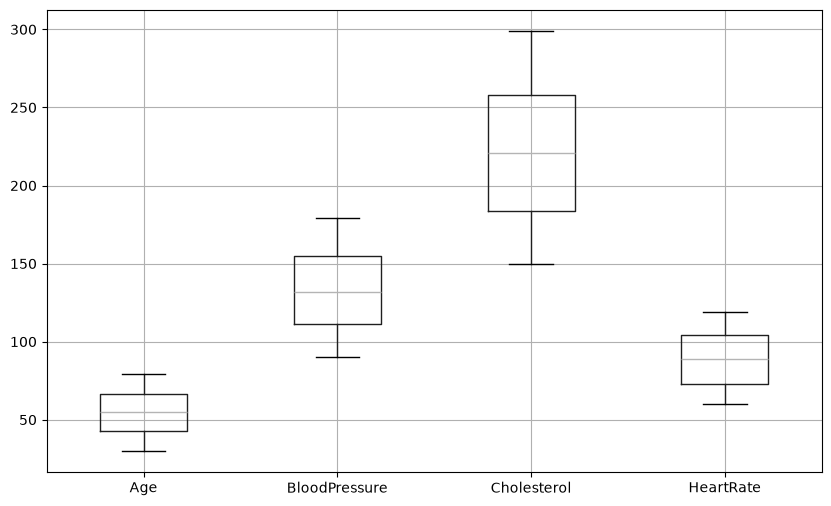

In [32]:
numericas.boxplot(figsize=(10, 6))
plt.show()

Encuentra la siguiente información para las variables categóricas:
- tabla de frecuencias
- valores únicos

In [33]:
print(data['Gender'].value_counts())
print(data['Gender'].unique())

Gender
0    266
1    234
Name: count, dtype: int64
[1 0]


In [34]:
print(data['HeartDisease'].value_counts())
print(data['HeartDisease'].unique())

HeartDisease
1    300
0    200
Name: count, dtype: int64
[1 0]


## Referencia

Dataset original tomado de: https://www.kaggle.com/datasets/shantanugarg274/heart-prediction-dataset-quantum